In [ ]:
!pip install -q kaggle
!pip install -q split-folders

In [ ]:
!mkdir -p ~/.kaggle

!cp kaggle.json ~/.kaggle/

!chmod 600 ~/.kaggle/kaggle.json

In [ ]:
!kaggle datasets download -d afridirahman/brain-stroke-ct-image-dataset

Dataset URL: https://www.kaggle.com/datasets/afridirahman/brain-stroke-ct-image-dataset
License(s): unknown
100% 60.4M/60.4M [00:00<00:00, 182MB/s]



In [ ]:
!unzip -q brain-stroke-ct-image-dataset.zip

In [ ]:
normal_path='/content/Brain_Data_Organised/Normal'
stroke_path='/content/Brain_Data_Organised/Stroke'

In [ ]:
import os
normal_folder=os.listdir(normal_path)
stroke_folder=os.listdir(stroke_path)

In [ ]:
print(len(normal_folder))
print(len(stroke_folder))

1551
950


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report,confusion_matrix,accuracy_score
import tensorflow as tf
from keras import Sequential
from keras.layers import Input,Dense,Conv2D,MaxPooling2D,Flatten,BatchNormalization,Dropout
from keras.preprocessing import image_dataset_from_directory

import warnings
warnings.filterwarnings('ignore')

In [ ]:
from PIL import Image
data=[]
for i in normal_folder:
  image=Image.open('/content/Brain_Data_Organised/Normal/'+i)
  image=image.resize((224,224))
  image=image.convert('RGB')
  image=np.array(image)
  data.append(image)

for i in stroke_folder:
  image=Image.open('/content/Brain_Data_Organised/Stroke/'+i)
  image=image.resize((224,224))
  image=image.convert('RGB')
  image=np.array(image)
  data.append(image)

In [ ]:
print(len(data))
print(data[0].shape)

2501
(224, 224, 3)


array([[[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       ...,

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]]], dtype=uint8)
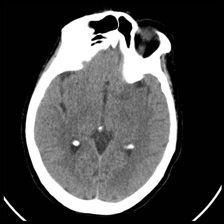

In [ ]:
data[0]

In [ ]:
normal_label=[0]*len(normal_folder)
stroke_label=[1]*len(stroke_folder)
target_label=normal_label+stroke_label
len(target_label)

2501

In [ ]:
X=np.array(data)
y=np.array(target_label)

In [ ]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,shuffle=True)

In [ ]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(2000, 224, 224, 3)
(501, 224, 224, 3)
(2000,)
(501,)


In [ ]:
X_train_scaled=X_train/255
X_test_scaled=X_test/255

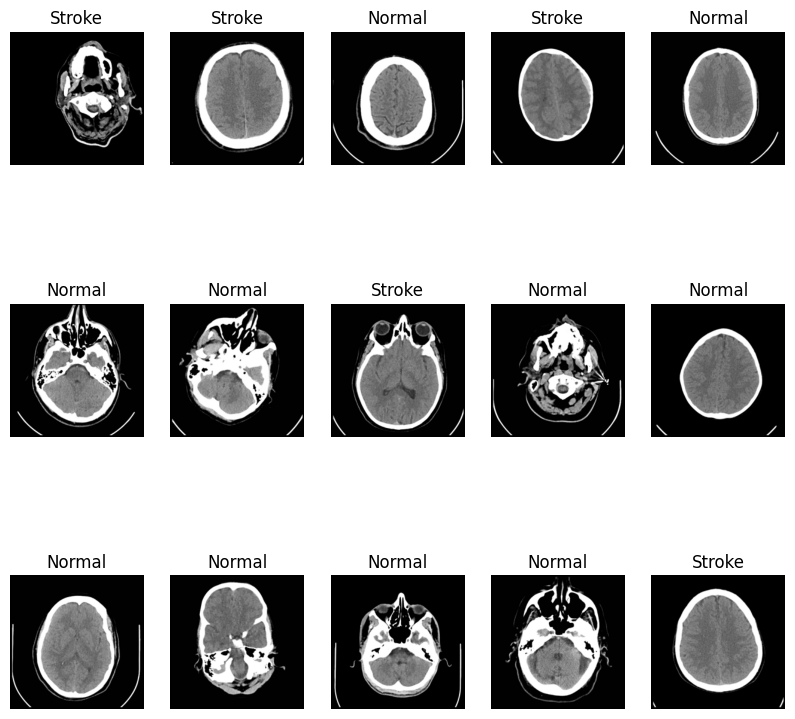

In [ ]:
#VISUALIZE
class_labels=['Normal','Stroke']
plt.figure(figsize=(10,10))
for i in range(15):
  plt.subplot(3,5,i+1)
  plt.imshow(X_train[i])
  plt.title(class_labels[y_train[i]])
  plt.axis("off")

In [ ]:
#MODEL
model=Sequential()
model.add(Conv2D(filters=128,kernel_size=(3,3),padding='valid',activation='relu',input_shape=(224,224,3)))
model.add(MaxPooling2D(pool_size=(2,2)))

model.add(Conv2D(filters=64,kernel_size=(3,3),padding='valid',activation='relu'))
model.add(MaxPooling2D(pool_size=(2,2)))

model.add(Conv2D(filters=32,kernel_size=(3,3),padding='valid',activation='relu'))
model.add(MaxPooling2D(pool_size=(2,2)))

model.add(Flatten())
model.add(Dense(256,activation='relu'))
model.add(Dropout(0.4))
model.add(Dense(128,activation='relu'))
model.add(Dropout(0.4))
model.add(Dense(1,activation='sigmoid'))

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 222, 222, 128)  │         3,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 111, 111, 128)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 109, 109, 64)   │        73,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 52, 52, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 26, 26, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 21632)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 256)            │     5,538,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,666,913 (21.62 MB)

 Trainable params: 5,666,913 (21.62 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from keras.optimizers import Adam

In [ ]:
model.compile(optimizer=Adam(learning_rate=0.0001),loss='binary_crossentropy',metrics=['accuracy'])

In [ ]:
from keras.callbacks import EarlyStopping
early_stop=EarlyStopping(monitor='val_loss',patience=5,restore_best_weights=True)

In [ ]:
history=model.fit(X_train_scaled,y_train,batch_size=32,epochs=12,validation_data=(X_test_scaled,y_test))

Epoch 1/12
63/63 ━━━━━━━━━━━━━━━━━━━━ 16s 188ms/step - accuracy: 0.6315 - loss: 0.6521 - val_accuracy: 0.6287 - val_loss: 0.6280
Epoch 2/12
63/63 ━━━━━━━━━━━━━━━━━━━━ 8s 125ms/step - accuracy: 0.6575 - loss: 0.5966 - val_accuracy: 0.7126 - val_loss: 0.5322
Epoch 3/12
63/63 ━━━━━━━━━━━━━━━━━━━━ 8s 127ms/step - accuracy: 0.7505 - loss: 0.4983 - val_accuracy: 0.8244 - val_loss: 0.4324
Epoch 4/12
63/63 ━━━━━━━━━━━━━━━━━━━━ 9s 135ms/step - accuracy: 0.8145 - loss: 0.3995 - val_accuracy: 0.8782 - val_loss: 0.2996
Epoch 5/12
63/63 ━━━━━━━━━━━━━━━━━━━━ 8s 127ms/step - accuracy: 0.8795 - loss: 0.2923 - val_accuracy: 0.8982 - val_loss: 0.2635
Epoch 6/12
63/63 ━━━━━━━━━━━━━━━━━━━━ 8s 125ms/step - accuracy: 0.9180 - loss: 0.2225 - val_accuracy: 0.9361 - val_loss: 0.1682
Epoch 7/12
63/63 ━━━━━━━━━━━━━━━━━━━━ 8s 126ms/step - accuracy: 0.9285 - loss: 0.1649 - val_accuracy: 0.9401 - val_loss: 0.1569
Epoch 8/12
63/63 ━━━━━━━━━━━━━━━━━━━━ 8s 126ms/step - accuracy: 0.9490 - loss: 0.1333 - val_accuracy: 0

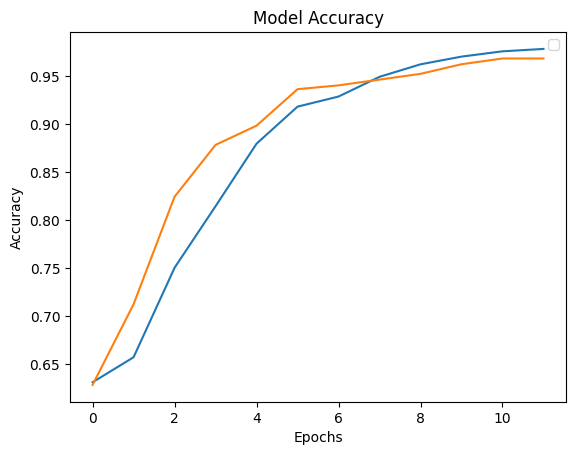

In [ ]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epochs')
plt.legend()

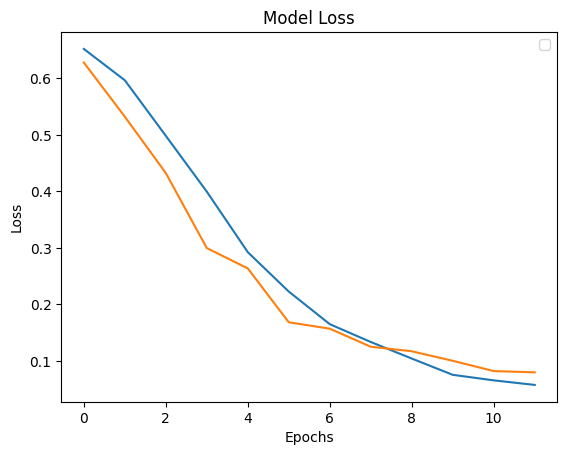

In [ ]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epochs')
plt.legend()


In [ ]:
loss,acc=model.evaluate(X_test_scaled,y_test)
print('Loss:',loss)
print('Accuracy:',acc)

loss,acc=model.evaluate(X_train_scaled,y_train)
print('Loss:',loss)
print('Accuracy:',acc)


16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - accuracy: 0.9681 - loss: 0.0796
Loss: 0.07961360365152359
Accuracy: 0.9680638909339905
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 37ms/step - accuracy: 0.9940 - loss: 0.0245
Loss: 0.024484388530254364
Accuracy: 0.9940000176429749


In [ ]:
y_pred_test=model.predict(X_test_scaled)
y_pred_test_label=[1 if i>=0.5 else 0 for i in y_pred_test]
print("ACTUAL LABEL:")
print(y_test[:10])
print("PREDICTED LABEL:")
print(y_pred_test_label[:10])

16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 51ms/step
ACTUAL LABEL:
[0 1 0 0 0 1 1 0 1 0]
PREDICTED LABEL:
[0, 1, 0, 0, 0, 1, 1, 0, 1, 0]


In [ ]:
from sklearn.metrics import classification_report
print(classification_report(y_test,y_pred_test_label))

              precision    recall  f1-score   support

           0       0.97      0.98      0.97       305
           1       0.96      0.95      0.96       196

    accuracy                           0.97       501
   macro avg       0.97      0.97      0.97       501
weighted avg       0.97      0.97      0.97       501



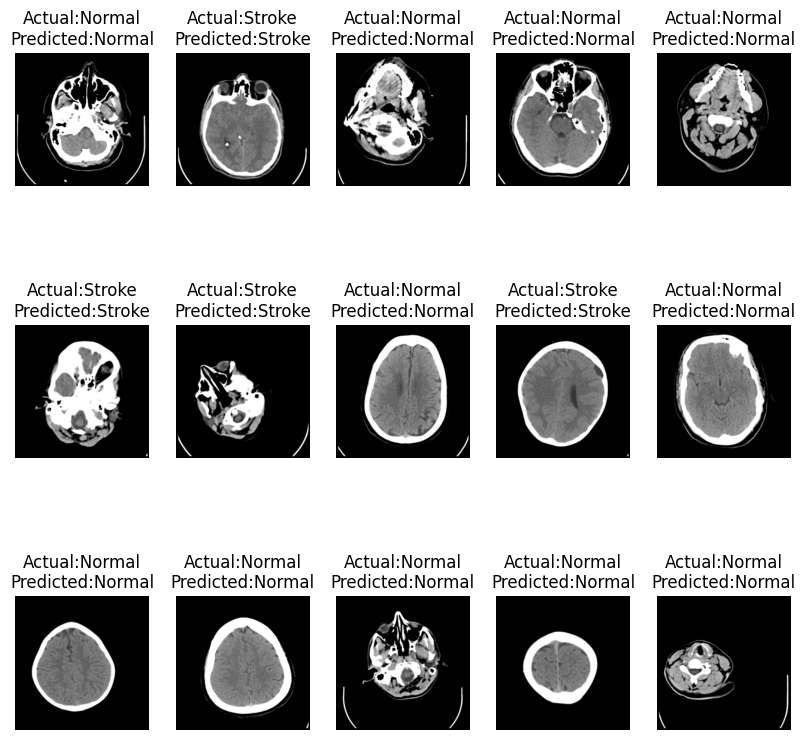

In [ ]:
#PREDICTIONS
class_labels=['Normal','Stroke']
plt.figure(figsize=(10,10))
for i in range(15):
  plt.subplot(3,5,i+1)
  plt.imshow(X_test[i])
  plt.title(f"Actual:{class_labels[y_test[i]]}\nPredicted:{class_labels[y_pred_test_label[i]]}")
  plt.axis("off")
plt.show()

In [ ]:
model.save("stroke_model.keras")
import json
with open('stroke_class_labels.json','w') as f:
  json.dump(class_labels,f)

In [ ]:
import pickle

with open("history.pkl", "wb") as f:
    pickle.dump(history.history, f)

In [ ]:
from google.colab import files

files.download("stroke_model.keras")
files.download("stroke_class_labels.json")
files.download("history.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>